# 24 — Synthetic Historical Control on the monthly latent panel with stage 1 learned by a generator

Stage 1 of the paper (slide 6: covariate step and local-linear kernel smoothing of the site's own months, giving
ℓ̂_t for t ≤ T0) is replaced by a neural network f(l_i, t) trained across sites on the pre-period rows: l_i is a
learned 32-value code per site, t enters as a learned 8-value embedding per period, two hidden layers of 256, and
two output heads run as two arms — **mlp** (a fully connected layer to the 980 values) and **cnn** (a convolutional
decoder: 32 × 7 × 7 → transposed convolution to 32 × 14 × 14 → 3 × 3 convolution to 5 × 14 × 14). Loss: mean squared
error + 1e-3·mean‖l_i‖²; Adam 1e-3, weight decay 1e-4 on the weights; batch 64; up to 5000 epochs with the best
epoch kept and a stop after 50 epochs without improvement on 10 % of the site-months held out at random; seed 0.
One generator per fit: T0 = P10 (effect), P08 (validation n = 2), P07 (validation n = 3); a generator never sees a
period after its T0. Stage 2 (blocks, stepwise matching, weights, counterfactual) is `panel_shc.py` unchanged.

**kernel = the 4 September run (existing CSVs, not recomputed); mlp / cnn = the two generator arms.** Treated sites.


In [1]:
import numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 80)
ARMS = {"kernel": "", "mlp": "_mlp", "cnn": "_cnn"}
F = {a: pd.read_csv(f"panel_shc_fits{s}.csv") for a, s in ARMS.items()}
E = {a: pd.read_csv(f"panel_shc_effects{s}.csv") for a, s in ARMS.items()}
S = {a: pd.read_csv(f"panel_shc_summary{s}.csv") for a, s in ARMS.items()}
G = {a: pd.read_csv(f"panel_generator{s}.csv") for a, s in ARMS.items() if a != "kernel"}
CV = {a: pd.read_csv(f"panel_generator_curves{s}.csv") for a, s in ARMS.items() if a != "kernel"}
for a in ARMS:
    F[a] = F[a][F[a].group == "treatment"]
print({a: len(F[a]) for a in ARMS}, "treated fits per arm")
KEYS = ["fill", "sensor", "n", "m"]
def side(cols, arms=("kernel", "mlp", "cnn"), sel=None):
    parts = []
    for a in arms:
        t = S[a] if sel is None else S[a][sel(S[a])]
        parts.append(t.set_index(KEYS)[cols].add_suffix(f" | {a}"))
    out = parts[0].join(parts[1:], how="outer")
    return out[[f"{c} | {a}" for c in cols for a in arms]].reset_index()

{'kernel': 702, 'mlp': 702, 'cnn': 702} treated fits per arm


## 0. The generator: what it learned (held-out 10 % of the site-months of each fit)

R² is 1 − (held-out squared error) / (held-out variance about the held-out cells' own mean per coordinate), pooled over the coordinates of a channel; `n_filled` counts months whose composite was unusable and which the generator fills (the kernel left them NaN). The cnn head sits on a plateau at the data's mean for 250 to 1000 epochs before it learns; where the 50-epoch stopping rule fired inside that plateau the fit is marked **untrained** (held-out R² below 0.1) and the SHC numbers built on it are those of a generator that predicts each site's mean. The rule was kept as set on 11 September; the untrained fits are reported as such.

In [2]:
cols = ["fill", "sensor", "arm", "fit", "n_sites", "n_train", "n_held", "n_filled", "params", "epochs_run", "best_epoch", "stop",
        "train_mse", "held_mse", "r2_all", "status"] + [f"r2_ch{c}" for c in range(1, 6)] + ["code_norm_mean", "device", "seconds"]
Gall = pd.concat(G.values()); Gall["status"] = np.where(Gall.r2_all < 0.1, "UNTRAINED (stopped on the plateau)", "trained")
print(Gall.sort_values(["fill", "sensor", "arm", "T0"], ascending=[True, True, True, False])[cols]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
UNTRAINED = {(r.fill, r.sensor, r.arm, int(r.T0)) for r in Gall.itertuples() if r.r2_all < 0.1}
print("untrained fits:", sorted(UNTRAINED))

    fill    sensor arm      fit  n_sites  n_train  n_held  n_filled  params  epochs_run  best_epoch     stop  train_mse  held_mse  r2_all                             status  r2_ch1  r2_ch2  r2_ch3  r2_ch4  r2_ch5  code_norm_mean device  seconds
chipmean sentinel1 cnn T0 = P10      132     1133     126        61  501429        1402        1352 patience     0.0567    0.0610  0.3044                            trained  0.3352  0.2910  0.5232  0.2386  0.1627          1.3034   cuda  93.2000
chipmean sentinel1 cnn T0 = P08      132      895     100        61  501413        1315        1265 patience     0.0510    0.0574  0.3453                            trained  0.3683  0.3237  0.5566  0.2919  0.2167          1.3747   cuda  68.9000
chipmean sentinel1 cnn T0 = P07      132      777      86        61  501405         451         401 patience     0.0869    0.0869 -0.0018 UNTRAINED (stopped on the plateau)  0.0040  0.0024  0.0032 -0.0110 -0.0084          0.1902   cuda  22.3000
chipmean sentinel1 m

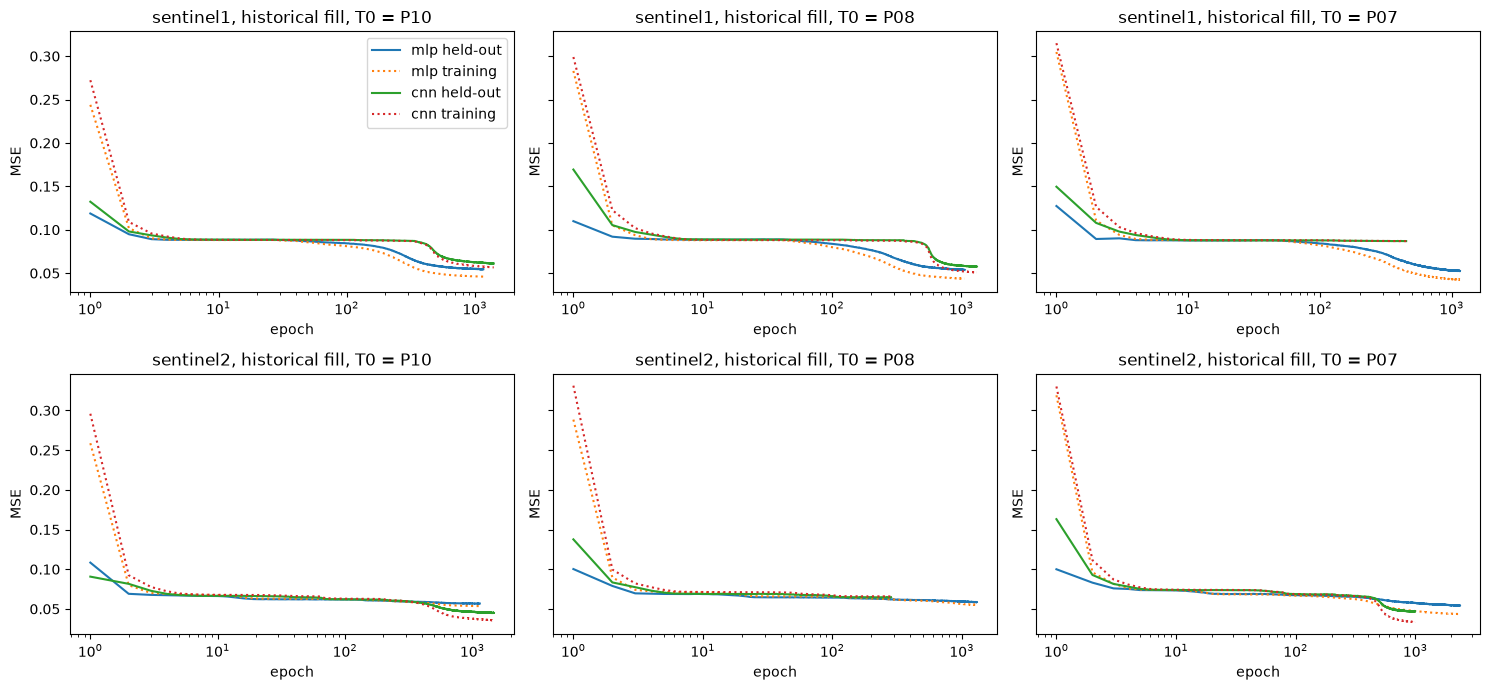

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for r, sensor in enumerate(("sentinel1", "sentinel2")):
    for c, T0 in enumerate((10, 8, 7)):
        ax = axes[r, c]
        for a in ("mlp", "cnn"):
            cv = CV[a][(CV[a].sensor == sensor) & (CV[a].fill == "histfill") & (CV[a].T0 == T0)]
            ax.plot(cv.epoch, cv.held_mse, label=f"{a} held-out"); ax.plot(cv.epoch, cv.train_mse, ":", label=f"{a} training")
        ax.set_title(f"{sensor}, historical fill, T0 = P{T0:02d}"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.set_xscale("log")
        if r == 0 and c == 0: ax.legend()
plt.tight_layout(); plt.savefig("panel_generator_curves.png", dpi=110); plt.show()

## 1. Which block is chosen, and the pre-period matching MSE of eq 31 of the selected block (treated sites, T0 = P10)

`most_recent_only` = treated fits where block 1 is selected alone.

In [4]:
cols = ["most_recent_only", "n_selected_mean", "mse_pre_mean", "n_eff_mean"]
for sensor in ("sentinel1", "sentinel2"):
    print(f"\n=== {sensor} ===")
    print(side(cols, sel=lambda t, s=sensor: t.sensor == s).sort_values(["fill", "n", "m"]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))


=== sentinel1 ===
    fill    sensor  n  m  most_recent_only | kernel  most_recent_only | mlp  most_recent_only | cnn  n_selected_mean | kernel  n_selected_mean | mlp  n_selected_mean | cnn  mse_pre_mean | kernel  mse_pre_mean | mlp  mse_pre_mean | cnn  n_eff_mean | kernel  n_eff_mean | mlp  n_eff_mean | cnn
chipmean sentinel1  2  2                         12                      12                       0                    1.0000                 1.0000                 1.0833                 0.0043              0.0000              0.0000               1.0000            1.0000            1.0833
chipmean sentinel1  2  3                         12                       0                       0                    1.0000                 1.0000                 1.0000                 0.0042              0.0000              0.0000               1.0000            1.0000            1.0000
chipmean sentinel1  2  4                         12                       0                      12      

## 2. Prediction error (temporal validation: fit on P01–P(10 − n), predict the last n pre-hurricane months; RMSE over the 980 coordinates between the observed latent and the synthetic counterfactual, mean over the held-out months and the treated sites)

Own mean = the site's own P01–P(10 − n) mean used as the prediction (the same in every arm).

In [5]:
cols = ["placebo_rmse", "placebo_rmse_raw", "placebo_beats_ownmean"]
for sensor in ("sentinel1", "sentinel2"):
    t = side(cols, sel=lambda t, s=sensor: t.sensor == s)
    own = S["kernel"][S["kernel"].sensor == sensor].set_index(KEYS)["placebo_rmse_ownmean"]
    t = t.set_index(KEYS).join(own).reset_index()
    t["cnn generator"] = ["UNTRAINED" if (r.fill, sensor, "cnn", 10 - int(r.n)) in UNTRAINED else "trained" for r in t.itertuples()]
    print(f"\n=== {sensor} ===  (the validation at n uses the generator with T0 = 10 - n)")
    print(t.sort_values(["fill", "n", "m"]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))


=== sentinel1 ===  (the validation at n uses the generator with T0 = 10 - n)
    fill    sensor  n  m  placebo_rmse | kernel  placebo_rmse | mlp  placebo_rmse | cnn  placebo_rmse_raw | kernel  placebo_rmse_raw | mlp  placebo_rmse_raw | cnn  placebo_beats_ownmean | kernel  placebo_beats_ownmean | mlp  placebo_beats_ownmean | cnn  placebo_rmse_ownmean cnn generator
chipmean sentinel1  2  2                 0.2303              0.2392              0.2490                     0.2666                  0.2887                  0.2916                         11.0000                       4.0000                       0.0000                0.2360       trained
chipmean sentinel1  2  3                 0.2303              0.2392              0.2490                     0.2666                  0.2752                  0.2920                         11.0000                       4.0000                       0.0000                0.2360       trained
chipmean sentinel1  2  4                 0.2303        

## 3. Prediction error per held-out month (m = 4, historical fill, mean over treated sites)

In [6]:
rows = []
for a in ARMS:
    T = F[a][(F[a].fill == "histfill") & (F[a].m == 4) & (F[a].placebo_ok == True)]
    for (sensor, n), g in T.groupby(["sensor", "n"]):
        r = {"sensor": sensor, "n": n, "arm": a}
        for q in (8, 9, 10):
            c = f"placebo_rmse_P{q:02d}"
            if c in g: r[f"P{q:02d}"] = g[c].mean()
        r["mean"] = g.placebo_rmse.mean(); r["own mean"] = g.placebo_rmse_ownmean.mean()
        rows.append(r)
print(pd.DataFrame(rows).sort_values(["sensor", "n", "arm"]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

   sensor  n    arm    P08    P09    P10   mean  own mean
sentinel1  2    cnn    NaN 0.2460 0.2516 0.2488    0.2360
sentinel1  2 kernel    NaN 0.2229 0.2377 0.2303    0.2360
sentinel1  2    mlp    NaN 0.2359 0.2425 0.2392    0.2360
sentinel1  3    cnn 0.2987 0.2988 0.2999 0.2991    0.2452
sentinel1  3 kernel 0.2396 0.2442 0.2595 0.2478    0.2452
sentinel1  3    mlp 0.2442 0.2450 0.2502 0.2465    0.2452
sentinel2  2    cnn    NaN 0.2358 0.2350 0.2354    0.2439
sentinel2  2 kernel    NaN 0.2093 0.2252 0.2173    0.2439
sentinel2  2    mlp    NaN 0.2310 0.2339 0.2324    0.2439
sentinel2  3    cnn 0.2640 0.2511 0.2256 0.2469    0.2525
sentinel2  3 kernel 0.2232 0.2394 0.2488 0.2371    0.2525
sentinel2  3    mlp 0.2466 0.2410 0.2276 0.2384    0.2525


## 4. Per treated site, n = 2, m = 4, historical fill: prediction error and own mean, kernel | mlp | cnn

In [7]:
def per_site(a):
    T = F[a][(F[a].fill == "histfill") & (F[a].n == 2) & (F[a].m == 4) & (F[a].placebo_ok == True)]
    return T.set_index(["sensor", "site"])[["placebo_rmse", "placebo_rmse_ownmean", "selected"]].rename(
        columns={"placebo_rmse": f"prediction error | {a}", "placebo_rmse_ownmean": "own mean", "selected": f"selected | {a}"})
t = per_site("kernel").join(per_site("mlp").drop(columns="own mean")).join(per_site("cnn").drop(columns="own mean"))
print(t.round(3).to_string())

                          prediction error | kernel  own mean selected | kernel  prediction error | mlp selected | mlp  prediction error | cnn selected | cnn
sensor    site                                                                                                                                               
sentinel1 treatment_0015                      0.253     0.256                 1                   0.255            4 1                   0.261              1
          treatment_0016                      0.251     0.249                 1                   0.250            4 1                   0.257              1
          treatment_0017                      0.224     0.233                 1                   0.243            4 1                   0.247              1
          treatment_0018                      0.214     0.229                 1                   0.229            4 1                   0.243              1
          treatment_0019                      0.231 

## 5. λ = observed − counterfactual at the post-hurricane months (treated sites only): ‖λ‖/√980 per month, mean over sites, and per channel (m = 4)

In [8]:
def eff(a):
    g = E[a][(E[a].m == 4) & (E[a].group == "treatment")]
    return g.groupby(["sensor", "fill", "n", "post_period"]).agg(sites=("site", "nunique"), lam_rms=("delta_rms", "mean"), lam_raw=("delta_raw_rms", "mean"))
t = eff("kernel").join(eff("mlp"), rsuffix=" | mlp").join(eff("cnn"), rsuffix=" | cnn")
print(t.round(4).to_string())
ch = [f"delta_ch{c}" for c in range(1, 6)]
rows = []
for a in ARMS:
    g = E[a][(E[a].m == 4) & (E[a].n == 2) & (E[a].fill == "histfill") & (E[a].group == "treatment")]
    for (sensor, q), gg in g.groupby(["sensor", "post_period"]):
        rows.append({"sensor": sensor, "post month": q, "arm": a, **{c: gg[c].mean() for c in ch}})
print("\nper-channel mean of lambda:")
print(pd.DataFrame(rows).sort_values(["sensor", "post month", "arm"]).round(4).to_string(index=False))

                                  sites  lam_rms  lam_raw  sites | mlp  lam_rms | mlp  lam_raw | mlp  sites | cnn  lam_rms | cnn  lam_raw | cnn
sensor    fill     n post_period                                                                                                               
sentinel1 chipmean 2 P11             12   0.2086   0.2595           12         0.2206         0.2371           12         0.2450         0.2595
                     P12             12   0.2648   0.3007           12         0.2445         0.2713           12         0.2607         0.3007
                   3 P11             12   0.2037   0.2686           12         0.2207         0.2534           12         0.2450         0.2686
                     P12             12   0.2528   0.3008           12         0.2445         0.2788           12         0.2607         0.3008
                     P13             12   0.2644   0.3027           12         0.2229         0.2746           12         0.2417        

## 6. Per treated site, n = 2, m = 4, historical fill: ‖λ‖/√980 at P11 and P12, kernel | mlp | cnn

In [9]:
def lam_site(a):
    T = F[a][(F[a].fill == "histfill") & (F[a].n == 2) & (F[a].m == 4) & (F[a].ok == True)]
    return T.set_index(["sensor", "site"])[["delta_rms_k1", "delta_rms_k2"]].rename(columns={"delta_rms_k1": f"P11 | {a}", "delta_rms_k2": f"P12 | {a}"})
print(lam_site("kernel").join(lam_site("mlp")).join(lam_site("cnn")).round(3).to_string())

                          P11 | kernel  P12 | kernel  P11 | mlp  P12 | mlp  P11 | cnn  P12 | cnn
sensor    site                                                                                  
sentinel1 treatment_0015         0.246         0.289      0.248      0.259      0.257      0.270
          treatment_0016         0.211         0.278      0.222      0.253      0.245      0.263
          treatment_0017         0.200         0.253      0.209      0.235      0.233      0.249
          treatment_0018         0.194         0.255      0.221      0.243      0.240      0.256
          treatment_0019         0.206         0.266      0.222      0.257      0.242      0.269
          treatment_0020         0.213         0.269      0.219      0.239      0.247      0.261
          treatment_0021         0.214         0.275      0.225      0.250      0.247      0.262
          treatment_0022         0.221         0.278      0.225      0.254      0.263      0.271
          treatment_0023      